Необходимо создать и обучить нейросеть распознавать рукописные цифры.

В качестве набора данных предполагается использовать [MNIST](https://ru.wikipedia.org/wiki/MNIST_(%D0%B1%D0%B0%D0%B7%D0%B0_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85)) копия которого находится в библиотеке [keras](https://keras.io/api/datasets/mnist/)

В процессе практики необходимо загрузить набор данных, преобразовать входной набор в формат, подходящий для обучения нейронной сети (преобразовать картинку в вектор-столбец и выполнить нормализацию данных), подобрать подходящую архитектуру с учетом использования полносвязных слоев, произвести обучение и проверку

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


In [2]:
# загрузка датасета MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print('train size', x_train.shape, y_train.shape)
print('test size', x_test.shape, y_test.shape)

train size (60000, 28, 28) (60000,)
test size (10000, 28, 28) (10000,)


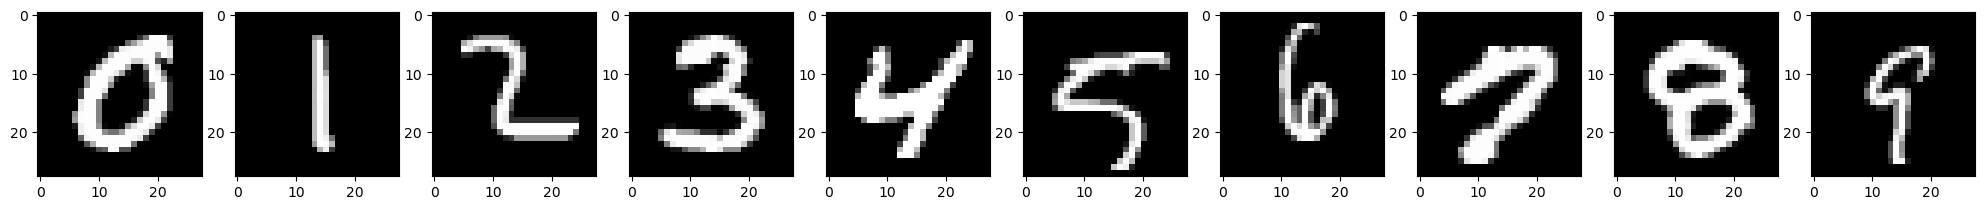

In [3]:
# вывод изображений каждого класса для ознакомления с датасетом
fig, axs = plt.subplots(1, 10, figsize=(25,3)) # создаем полотно для 10 графиков с размером 25 на 3
for i in range(10):
  label_indexes = np.where(y_train == i)[0] # получаем список из индексов положений класса i в y_train
  index = random.choice(label_indexes) # выбирает случайный индекс из списка созданного выше
  img = x_train[index] # выбираем из x_train нужное положение
  axs[i].imshow(Image.fromarray(img), cmap='gray') # выводим изображение

plt.show()

In [4]:
# подготовка данных

# преобразование в вектор
x_train_flat = x_train.reshape(x_train.shape[0], 28 * 28)
x_test_flat = x_test.reshape(x_test.shape[0], 28 * 28)

# нормализация значений
x_train_flat = x_train_flat.astype('float32') / 255.0
x_test_flat = x_test_flat.astype('float32') / 255.0

# one-hot encoding преобразование
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print('train size', x_train_flat.shape, y_train_cat.shape)
print('test size', x_test_flat.shape, y_test_cat.shape)


train size (60000, 784) (60000, 10)
test size (10000, 784) (10000, 10)


In [5]:
# создадим валидационную выборку размера 0.1 обучающей выборки

x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_flat,
    y_train_cat,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print('train size', x_tr.shape, y_tr.shape)
print('val size', x_val.shape, y_val.shape)

train size (54000, 784) (54000, 10)
val size (6000, 784) (6000, 10)


In [6]:
# построение нейронной сети

model = models.Sequential([
    layers.Input(shape=(784,)), # входной слой 784 нейрона
    layers.Dense(512, activation='relu'), # скрытый слой 512 нейронов, ReLU
    layers.Dropout(0.2), # dropout 20%
    layers.Dense(256, activation='relu'), # скрытый слой 256 нейронов, ReLU
    layers.Dropout(0.2), # dropout 20%
    layers.Dense(10, activation='softmax') # выходной слой 10 нейронов, Softmax
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# компиляция модели

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [8]:
# обучение модели

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    x_tr,
    y_tr,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9182 - loss: 0.2734 - val_accuracy: 0.9625 - val_loss: 0.1268
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9658 - loss: 0.1114 - val_accuracy: 0.9730 - val_loss: 0.0935
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9760 - loss: 0.0788 - val_accuracy: 0.9752 - val_loss: 0.0857
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9806 - loss: 0.0612 - val_accuracy: 0.9763 - val_loss: 0.0839
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9840 - loss: 0.0499 - val_accuracy: 0.9745 - val_loss: 0.0866
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9867 - loss: 0.0402 - val_accuracy: 0.9785 - val_loss: 0.0834
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9882 - loss: 0.0361 - val_accuracy: 0.9748 - val_loss: 0.0908
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9901 - loss: 0.0305 - val_accuracy: 0.

In [9]:
# оценка качества на тестовой выборке

test_loss, test_accuracy = model.evaluate(x_test_flat, y_test_cat, verbose=0)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')


Test loss: 0.0702
Test accuracy: 0.9800


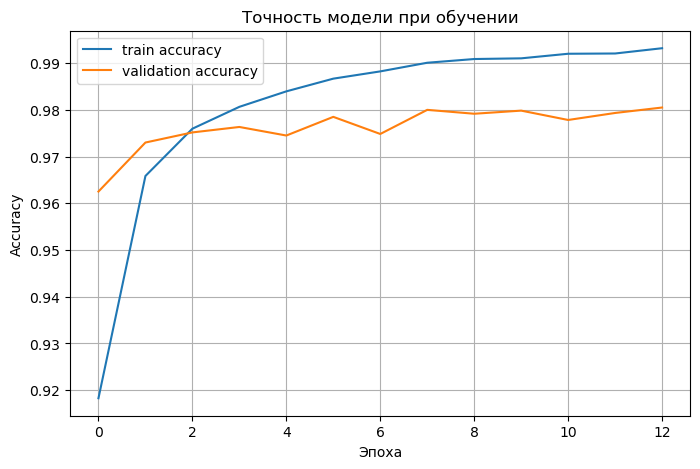

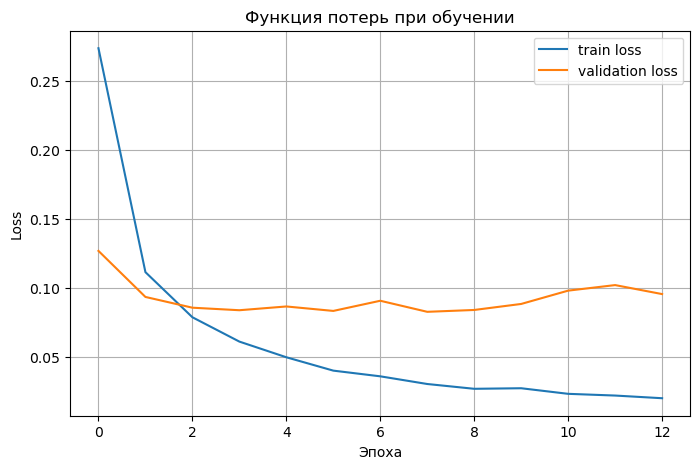

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.title('Точность модели при обучении')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.title('Функция потерь при обучении')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step


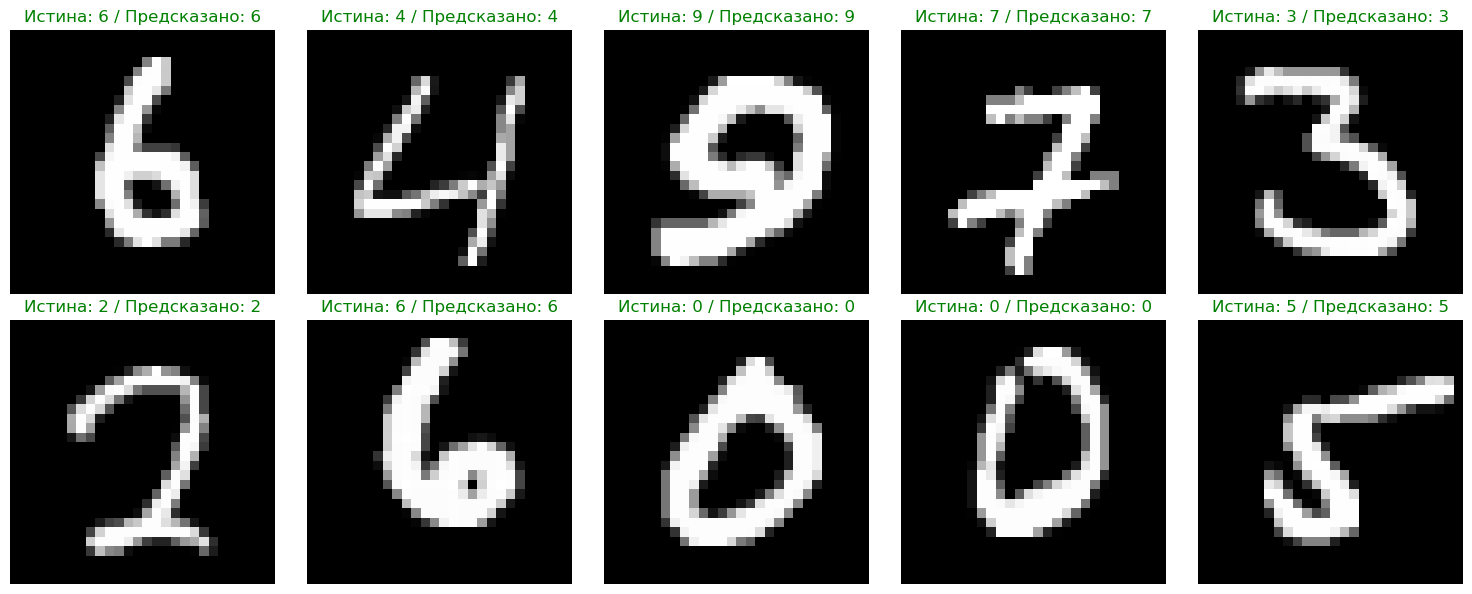

In [25]:
# примеры предсказаний

predictions = model.predict(x_test_flat)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(15, 6))

for i, idx in enumerate(random.sample(range(len(x_test)), 10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx], cmap='gray')
    true_label = y_test[idx]
    pred_label = predicted_labels[idx]
    color = 'green' if true_label == pred_label else 'red'
    plt.title(f'Истина: {true_label} / Предсказано: {pred_label}', color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()


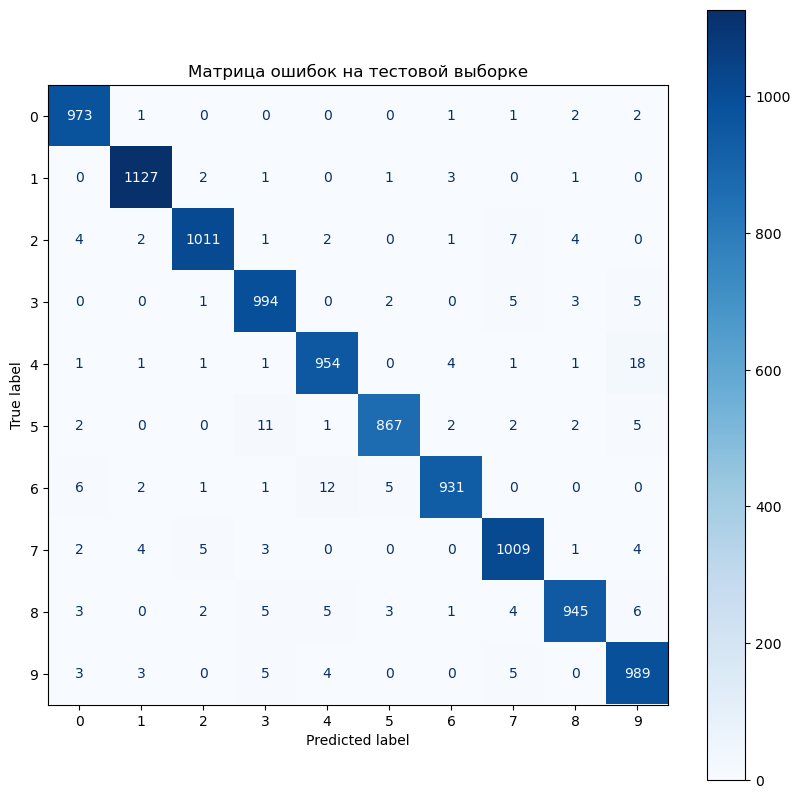

              precision    recall  f1-score   support

           0     0.9789    0.9929    0.9858       980
           1     0.9886    0.9930    0.9908      1135
           2     0.9883    0.9797    0.9839      1032
           3     0.9726    0.9842    0.9783      1010
           4     0.9755    0.9715    0.9735       982
           5     0.9875    0.9720    0.9797       892
           6     0.9873    0.9718    0.9795       958
           7     0.9758    0.9815    0.9787      1028
           8     0.9854    0.9702    0.9778       974
           9     0.9611    0.9802    0.9706      1009

    accuracy                         0.9800     10000
   macro avg     0.9801    0.9797    0.9798     10000
weighted avg     0.9801    0.9800    0.9800     10000



In [12]:
# Матрица ошибок и отчёт по классификации


cm = confusion_matrix(y_test, predicted_labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Матрица ошибок на тестовой выборке')
plt.show()

print(classification_report(y_test, predicted_labels, digits=4))
